# Use Inscopix python API to visualize cellmap and cell traces after time series PCA/ICA or CNMFe analysis and longitudinal registration
Prerequisite: run through time series and longitudinal registration templates using the demo dataset downloaded from Inscopix website or users' own recordings. The CNMFe or PCA/ICA cellset and other movies should have been pre-processed and saved before they are loaded in this data visualization template.

## Step 0. install jupyter notebook nbextensions to view table of contents


To best view and navigate this template, installing [jupyter notebook nbextensions](https://jupyter-contrib-nbextensions.readthedocs.io/en/latest/nbextensions/toc2/README.html) to show table of contents (TOC) sidebar is highly recommended.

1. After activating isxenv (conda activate isxenv), paste the following two lines into the command line one at a time (more instructions see [this link](https://jupyter-contrib-nbextensions.readthedocs.io/en/latest/install.html)).

```
pip install https://github.com/ipython-contrib/jupyter_contrib_nbextensions/tarball/master

jupyter contrib nbextension install --user
```

2. After the installation completes and "jupyter notebook" program is initiated (by typing "jupyter notebook" inside isxenv), a new nbextensions tab will appear to the right of the Files tab. Users can enable TOC within the nbextensions tab and toggle the TOC button on and off from the tool bar.


3. ExecuteTime is also recommended to be turned on in the nbextensions tab to view the execution time for each cell (or use %%time function instead in selective cells)

## Step 1. prepare files for analysis

### 1.1 import libraries

In [1]:
import isx  # Inscopix API
import os  # operating system
import json  # import json file
from pathlib import Path  # to work with dir
import numpy as np  # to manipulate data matrix
import numpy.matlib  # to manipulate data matrix
from scipy import stats  # calculate zscore
import pandas as pd  # data analysis library
import matplotlib.pyplot as plt  # data visualization
import matplotlib.lines as mlines  # figure legend styling

# to suppress warnings from the output window
import warnings
warnings.filterwarnings("ignore")

# to render the figures inside the current notebook
%matplotlib inline

### 1.2 load recordings dirs

### **USER INPUT REQUIRED (1 of 1)**

In [2]:
# make sure the output folder is the same as in previous analysis steps

Parent_folder_User_defined = Path(r'D:\demo')

output_dir = \
    Parent_folder_User_defined /  \
    "S1prism_AAV1_demo_with_LR" /  \
    "S1prism_AAV1_demo_v2_data" /  \
    "processed"

# load the recording dirs from the previous analysis steps

with open(output_dir / 'cnmfe_cellset_lr.json') as file:
    cnmfe_cellset_LRseries = json.load(file)

In [3]:
# store the series label, list of recordings and
# the No. of recordings in each series

day_labels = list(cnmfe_cellset_LRseries.keys())
recordings_series = list(cnmfe_cellset_LRseries.values())
num_rec_per_series = [len(child_list) for child_list in recordings_series]

# print series label and the recording No. for each series
print('Label of time series:', day_labels)
print('Number of recordings for each day:', num_rec_per_series)

# print the recording list from one example series

print("\n{} cnmfe cell set:".format(day_labels[0]))

for each in recordings_series[0]:
    print(Path(each).name)

Label of time series: ['day_1', 'day_4']
Number of recordings for each day: [4, 4]

day_1 cnmfe cell set:
recording_20160613_105808-PP-PP-PP-BP-MC-cnmfe-cellset-LR.isxd
recording_20160613_110507-PP-PP-PP-BP-MC-cnmfe-cellset-LR.isxd
recording_20160613_111207-PP-PP-PP-BP-MC-cnmfe-cellset-LR.isxd
recording_20160613_111907-PP-PP-PP-BP-MC-cnmfe-cellset-LR.isxd


## Step 2. Data visualization

### 2.1 define a function to extract cellmap and traces

In [4]:
def extract_cell_series(dataset, index_list=[], keep_gap=False,
                        Zscore=False, status_list = ['accepted', 'rejected', 'undecided']):

    """
    Extract timestamps, cell maps, and cell traces
        and filtered by input index list or cell accepted/rejected/undecided status

    Args:
        dataset: pca-ica or cnmfe time series dataset
        index_list: optional.
            unique or co-active cell index list.
            if no input, no cells will be filtered out.
        keep_gap: optional
            whether to keep the gap between each recording session
            Default set to False to concatenate timestamps
        Zscore: optional
            whether to convert traces to Zscore scale
            Default set to False to not convert.
        status_list: status filter, default setting includes all categories
    Returns:
        series_timestamps: timestamps extracted from the .isxd movie series
            concatenated with or without session gap from all recordings
        cell_image_all: binarized cell maps from all cells
            H pixels x W pixels x cell number.
        cell_trace_all: frame by cell numpy matrix
            trace series from all cells
            Y axis scale is dependent on input cellset or Zscore setting
        start_per_session: start time of each recording
        cum_frame_num: cumulative recording frame number for the series
    """

    # initiate image holder and trace holder
    # based on image size, cell number and total frame number

    # retrieve cell number
    num_cells = isx.CellSet.read(dataset[0]).num_cells
    # get image size
    image_size = isx.CellSet.read(
        dataset[0]).get_cell_image_data(0).astype(np.float64)
    # get total frame number from the input series
    total_frame_num = 0
    for each in (dataset):
        total_frame_num += isx.CellSet.read(each).timing.num_samples

    # allocate memory for output image and trace matrix
    cell_image_all = np.empty(shape=(image_size.shape[0],
                                     image_size.shape[1], num_cells))
    cell_trace_all = np.empty(shape=(total_frame_num, num_cells))

    # initiate timestamp and
    # prepare to concatenate cell trace from all recordings in the series
    series_timestamps = []
    # session_start: index for session start
    # session_end: index for session end
    session_start, session_end, session_offset = 0, 0, 0

    # start_per_session: store the start time for each recording
    # cum_frame_num: store the cumulative sum of total frame No.
    # from the 1st to last recording
    start_per_session = np.zeros((len(dataset)), dtype='datetime64[us]')
    cum_frame_num = np.zeros(shape=(len(dataset)))

    # set cell filter to label cells that match the input index list
    # initiation with false boolean
    id_filter = [False for i in range(num_cells)]

    # loop through time series recordings to retrieve cellmaps and traces
    for recording_i, recording in enumerate(dataset):
        cell_set = isx.CellSet.read(recording)   # load one recording at a time

        # get start time of each recording and interval between start times
        start_per_session[recording_i] = cell_set.timing.start.to_datetime()
        session_start_delta = (start_per_session[recording_i] -
                      start_per_session[0]).item().total_seconds()

        # retrieve the relative timestamps from each recording
        session_timestamps_unadj = [offset.secs_float
                for offset in cell_set.timing.get_offsets_since_start()]

        session_end += cell_set.timing.num_samples
        cum_frame_num[recording_i] = session_end

        for index in range(num_cells):

            # store cellmaps, only need to retrieve from one recording
            # since they are the same for all recordings in the same series
            if recording_i == 0:
                if (((not index_list) or index in list(index_list)) and \
                (cell_set.get_cell_status(index) in status_list)):
                    id_filter[index] = True
                cell_image = \
                    cell_set.get_cell_image_data(index).astype(np.float64)
                # threshold the cell image to get binarized cellmap
                cell_image = cell_image > (0.8 * np.max(cell_image))
                # store cell maps
                cell_image_all[:, :, index] = cell_image

            # retrieve and store cell traces
            cell_trace = cell_set.get_cell_trace_data(index)
            cell_trace_all[session_start:session_end, index] = cell_trace

        # change start frame number to previous end frame
        # each reset [start:end] matches one recording
        # at the end of the loop all traces are concatenated
        session_start = session_end

        # concatenate timestamps by adjusting timing in each recording
        if keep_gap:
            session_offset = session_start_delta
            session_timestamps = [timepoint +
                    session_offset for timepoint in session_timestamps_unadj]
        else:
            # one extra frame was added so the start of new recording
            # and the end of previous recording does not overlap
            extra_frame = cell_set.timing.period.secs_float
            # session_offset starts with 0
            # so the timing of the first recording is not adjusted
            session_timestamps = [timepoint +
                    session_offset for timepoint in session_timestamps_unadj]
            session_offset += max(session_timestamps_unadj) + extra_frame

        # concatenate timestamps
        series_timestamps += session_timestamps

    # Optional: convert to Zscore
    if Zscore:
        cell_trace_all = stats.zscore(cell_trace_all)

    return (series_timestamps, cell_image_all[:, :, id_filter],
            cell_trace_all[:, id_filter], start_per_session, cum_frame_num)

### 2.2 Keep time gap between recordings in the time series

['2016-06-13T10:58:08.225000' '2016-06-13T11:05:07.440000'
 '2016-06-13T11:12:07.101000' '2016-06-13T11:19:07.483000']


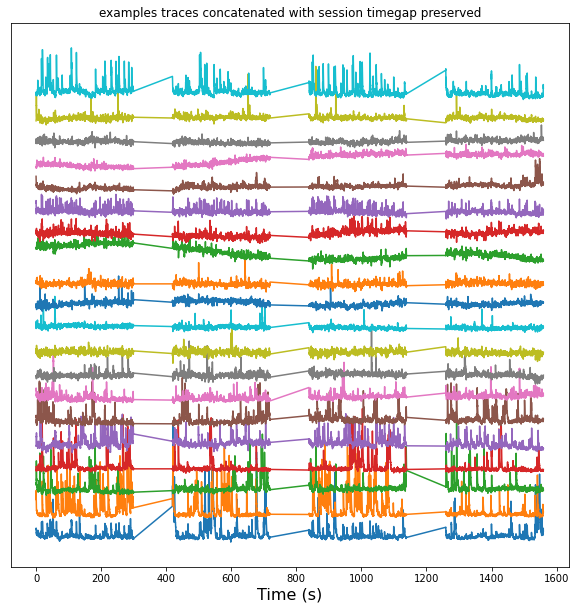

In [12]:
fig = plt.figure(figsize=(10, 10))

# get timestamps and traces and set keep_gap option to True
series_timestamps, _, series_traces, start_per_session, _ = extract_cell_series(
        cnmfe_cellset_LRseries["day_1"], keep_gap=True)

# plot example traces
offset = 0
for cell in range(20):
    plt.plot(series_timestamps, series_traces[:, cell]-offset)
    offset -= 40  # separate the Yaxis for each trace
    plt.title('examples traces concatenated with session timegap preserved',
              fontsize=12)
    plt.xlabel('Time (s)', fontsize=16)
    plt.yticks([])
print(start_per_session)

### 2.3 Zscore conversion for cell traces

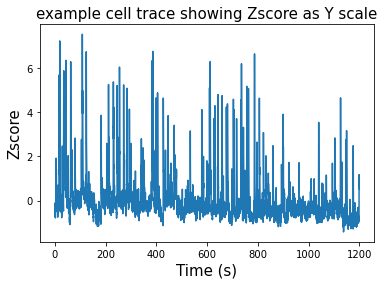

In [6]:
fig = plt.figure(figsize=(6, 4))

# get timestamps and traces and set Zscore option to True
# keep_gap option to False
series_timestamps, _, series_traces, _, _ = extract_cell_series(
        cnmfe_cellset_LRseries["day_1"], keep_gap=False, Zscore=True)

# plot an example trace
offset = 0
plt.plot(series_timestamps, series_traces[:, cell]-offset*0)
offset -= 6  # separate the Yaxis for each trace
plt.title('example cell trace showing Zscore as Y scale', fontsize=15)
plt.xlabel('Time (s)', fontsize=15)
plt.ylabel('Zscore', fontsize=15)
plt.show()

# print(series_traces.shape)

### 2.4 plot traces using relative fluorescence Y scale

#### 2.4.1 define a function to calculate df/f0 values for each cellmap

In [7]:

def apply_contour(dataset, cell_map):
    """
    calculate df/f0 value
    given input cellmap and background dff movie
    similar to IDPS apply contour command

    Args:
        dataset: dff movie series
        cell_map: input cell map used as contour mask
                       to retrieve the trace value
    Returns:
        output: frame by cell trace matrix
                the trace values match the input dff movie.
    """

    # initiate total frame number
    total_frame_num = 0
    for recording in (dataset):
        total_frame_num += isx.Movie.read(recording).timing.num_samples

    # get image size
    image_size = isx.Movie.read(
        dataset[0]).get_frame_data(0)

    # store frames from all recordings in the dff series to dff_image_all
    # allocate memory for image and frame matrix to store dff movie frames
    dff_image_all = np.empty(shape=(image_size.shape[0],
                                    image_size.shape[1], total_frame_num))

    frame_counter = 0  # start from first frame with 0 index
    if frame_counter < total_frame_num:  # stop when last frame is saved
        # loop through time series recordings
        # to retrieve the image frames
        for recording in dataset:
            rec_frame_number = isx.Movie.read(recording).timing.num_samples
            for each_frame in range(rec_frame_number):
                frame = isx.Movie.read(recording).get_frame_data(each_frame)
                dff_image_all[:, :, frame_counter] = frame  # store the image frame
                frame_counter += 1  # move to next frame in the image container

    # linearize pixels in 2D space, convert from 3D to 2D: pixel by cell
    pixel_cell = np.reshape(cell_map, [-1, cell_map.shape[2]])
    # linearize pixels in 2D space, convert from 3D to 2D: pixel by frame
    pixel_frame = np.reshape(dff_image_all, [-1, dff_image_all.shape[2]])
    # pixel-wise multiplication, convert to 2D: cell by frame
    # each value store the sum product of non-zero pixels' multiplication
    cell_frame = np.einsum('ij,ik->jk', pixel_cell, pixel_frame, optimize=True)
    # calculate the pixel # for each cell
    # convert to 1D matrix, cell by 1 column
    cell_pixelnum = np.reshape(numpy.sum(pixel_cell, axis=0), [-1, 1])

    # get the mean pixel value for each frame
    output = cell_frame/cell_pixelnum
    # transpose to frame by cell matrix
    output = np.transpose(output)

    return output

#### 2.4.2 plot traces in relative fluorescence Y scale

In [8]:
# retrieve the cell maps and apply to dff movie to get df/f0 traces

with open(output_dir / 'dff_files_lr.json') as file:
    dff_files_lr = json.load(file)

series_timestamps, series_cell_map, trace_zscore, _, _ = extract_cell_series(
    cnmfe_cellset_LRseries["day_1"], Zscore=True)
trace_dff_scale = apply_contour(dff_files_lr["day_1"], series_cell_map)

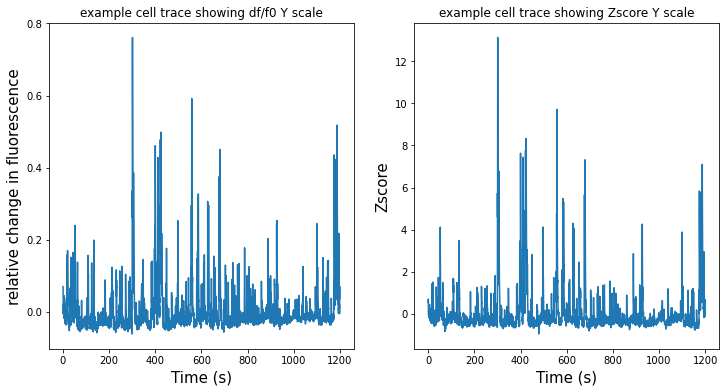


In addition to the scale difference, the raw trace shape 
might look different from processed traces after PCA/ICA or CNMFe analysis.
For example baseline drifting might get discarded as irrelevant PCA components during PCA/ICA analysis.
On the other hand, noise was modeled during cnmfe analysis and removed to render cleaner neuronal traces.


In [9]:
# plot an example of df/f0 scaled trace and compare with Zscore plot

fig = plt.figure(figsize=(12, 6))

plt.subplot(121)
plt.plot(series_timestamps, trace_dff_scale[:, 0])
plt.title('example cell trace showing df/f0 Y scale')
plt.xlabel('Time (s)', fontsize=15)
plt.ylabel('relative change in fluorescence', fontsize=15)

plt.subplot(122)
plt.plot(series_timestamps, trace_zscore[:, 0])
plt.title('example cell trace showing Zscore Y scale')
plt.xlabel('Time (s)', fontsize=15)
plt.ylabel('Zscore', fontsize=15)
plt.show()
print("""\nIn addition to the scale difference, the raw trace shape
might look different from processed traces after PCA/ICA or CNMFe analysis.
For example baseline drifting might get discarded as irrelevant PCA components during PCA/ICA analysis.
On the other hand, noise was modeled during cnmfe analysis and removed to render cleaner neuronal traces.""")

### 2.5 overlay time series cell maps with maximal projection frame from df/f recordings

The cell and frame number for the calcium trace matrix is 11994x423
The size of the cellmap matrix (pixelH x pixelW x cell number) is 230x265x423


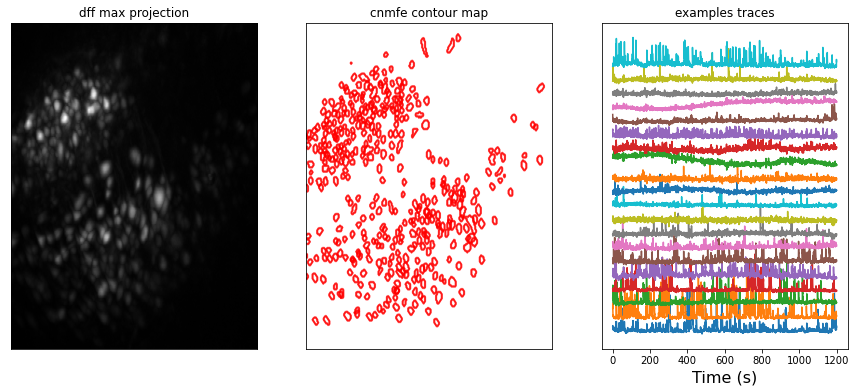

In [10]:
# load maximal projection files to plot as background image

with open(output_dir / 'maxdff_lr.json') as file:
    maxdff_lr = json.load(file)

# retrieve the calcium traces and cellmap matrix from cnmfe cellset
timestamps, cnmfe_cellmaps, cnmfe_traces, _, _ = extract_cell_series(
    cnmfe_cellset_LRseries["day_1"])
print("The cell and frame number for the calcium trace matrix is \
%dx%d" % cnmfe_traces.shape)
print("The size of the cellmap matrix (pixelH x pixelW x cell number\
) is %dx%dx%d" % cnmfe_cellmaps.shape)

# plot dff max projection and cnmfe contour map side by side
plt.figure(figsize=(15, 6))
ax1= plt.subplot(131)
# show dff movie max projection
maxdff = isx.Image.read(maxdff_lr["day_1"]).get_data()
ax1.imshow(maxdff, 'gray', aspect="auto")
plt.xticks([])
plt.yticks([])
plt.title('dff max projection')

# get contour image from each cell
ax2=plt.subplot(132, sharex=ax1,sharey=ax1)
for cell in range(cnmfe_cellmaps.shape[2]):
    ax2.contour(cnmfe_cellmaps[:, :, cell], colors='red', alpha=0.3)
plt.xticks([])
plt.yticks([])
plt.title('cnmfe contour map')

# plot sample traces
plt.subplot(133)
offset = 0
for cell in range(20):
    plt.plot(timestamps, cnmfe_traces[:, cell]-offset)
    offset -= 40  # separate the Yaxis for each trace
plt.title('examples traces', fontsize=12)
plt.xlabel('Time (s)', fontsize=16)
plt.yticks([])

fig.tight_layout()
plt.show()

### 2.6 overlay cellmaps from different categories from LR analysis

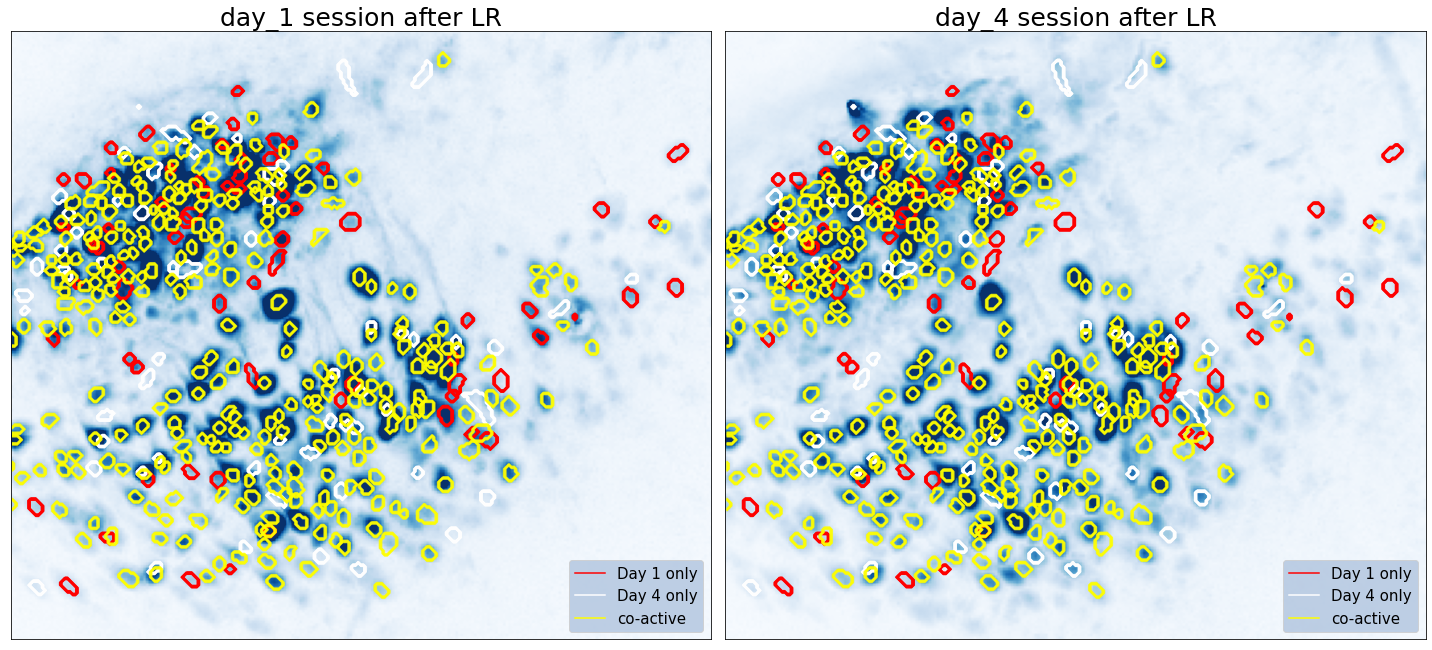

In [11]:
# load the session indexes
with open(output_dir / 'session_cell_index.json') as file:
    session_cell_index = json.load(file)

fig = plt.figure(figsize=(20, 20))

# set legend styles
day1_only = mlines.Line2D([], [], color='red', label='Day 1 only')
day4_only = mlines.Line2D([], [], color='white', label='Day 4 only')
co_active = mlines.Line2D([], [], color='yellow', label='co-active')

# overlay uniquely active or co-active cellmaps
# from day 1 and day 4 after LR

# series_i = 2 and 3 matching day 1 LR and day 4 LR series
# from the four datasets [0,1,2,3],

for series_i, day_label in enumerate(day_labels):
    exec('plt.subplot(12{})'.format(series_i+1))

    # plot background maximal projection image
    max_dff = isx.Image.read(maxdff_lr[day_label]).get_data()
    plt.imshow(max_dff, 'Blues', vmax=0.15)
    plt.xticks([])
    plt.yticks([])

    # retrieve cellmaps using unique or co-active index list as filter
    _, day_1_only, _, _, _ = extract_cell_series(
        cnmfe_cellset_LRseries[day_label], session_cell_index["day_1"])  # day 1 only
    _, day_4_only, _, _, _ = extract_cell_series(
        cnmfe_cellset_LRseries[day_label], session_cell_index["day_4"])  # day 4 only
    _, coactive, _, _, _ = extract_cell_series(
        cnmfe_cellset_LRseries[day_label], session_cell_index["day_1 and day_4"])  # day 1 and day 4 co-active

    # plot contour image for each category
    # day 1 only
    for cell in range(day_1_only.shape[2]):
        plt.contour(day_1_only[:, :, cell], colors='red', alpha=0.9)
        plt.xticks([])
        plt.yticks([])
    # day 4 only
    for cell in range(day_4_only.shape[2]):
        plt.contour(day_4_only[:, :, cell], colors='white', alpha=0.9)
        plt.xticks([])
        plt.yticks([])
    # day 1 and day 4 co-active
    for cell in range(coactive.shape[2]):
        plt.contour(coactive[:, :, cell], colors='yellow', alpha=0.6)
        plt.xticks([])
        plt.yticks([])
    plt.title('{}'.format(day_label + " session after LR"), fontsize=25)
    plt.legend(handles=[day1_only, day4_only, co_active],
               prop={'size': 15}, facecolor='lightsteelblue', loc='lower right')

fig.tight_layout()
plt.show()